# Rossmann Store Sales Forecasting Using Multivariate LSTM

**Project Domain:** Time Series Forecasting | Deep Learning | Retail Analytics

**Model:** Multivariate Long Short-Term Memory (LSTM)

## Problem Statement

Retail businesses experience fluctuations in Sales due to several factors, including customer demand, promotional activities, holidays, and store operating conditions. Accurately estimating future Sales is essential for effective inventory management, resource allocation, and business planning.

The objective of this project is to develop a deep learning-based time-series forecasting model that predicts future daily Sales for Rossmann stores using historical Sales data and relevant supporting features.

A Multivariate LSTM model is implemented to learn temporal patterns from historical Sales while considering additional information such as store activity, promotions, holidays, and calendar features.

The model is evaluated using chronological validation and recursive forecasting to assess its ability to predict consecutive future Sales values.

## Project Objectives

- Analyze historical Rossmann store Sales data to understand daily Sales patterns and trends.
- Convert the store-level dataset into a daily aggregate time-series dataset.
- Perform feature engineering using store activity, promotional information, holidays, and calendar features.
- Prepare sequential input data using a 30-day lookback window.
- Develop a Multivariate LSTM model to learn temporal patterns and relationships between input features.
- Train and evaluate the model using a chronological train-validation split.
- Analyze model performance using MAE, RMSE, and R² score.
- Perform recursive forecasting to estimate Sales for the future test period.
- Save the trained model, scalers, configuration, and prediction results for future use.

## Dataset Description

The project uses the Rossmann Store Sales dataset, which contains historical retail Sales information along with store-related and promotional details.

The dataset consists of three main files:

| File | Description |
|---|---|
| `train.csv` | Contains historical Sales, Customers, store information, promotional details, and dates. |
| `test.csv` | Contains the future dates and corresponding store-related information for which Sales must be forecasted. |
| `store.csv` | Contains additional information about individual stores, including store type, assortment, competition, and promotional details. |

The training data is merged with store information to create a comprehensive dataset for analysis and forecasting.

For this LSTM implementation, the data is aggregated at the daily level to forecast total Sales across all stores.

**Target Variable:** Sales

**Additional Features:** Open stores, promotional stores, school holidays, state holidays, and calendar-based features.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Rossmann_Sales_Forecasting"

DATA_PATH = os.path.join(PROJECT_PATH, "data")
OUTPUT_PATH = os.path.join(PROJECT_PATH, "outputs")
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
PREDICTION_PATH = os.path.join(PROJECT_PATH, "predictions")

# Create folders if they do not exist
os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(PREDICTION_PATH, exist_ok=True)

print("Project path:", PROJECT_PATH)

Project path: /content/drive/MyDrive/Rossmann_Sales_Forecasting


## Install and import libraries

In [3]:
%pip install -q statsmodels scikit-learn tensorflow joblib

In [4]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Preprocessing
from sklearn.preprocessing import MinMaxScaler

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Saving files
import joblib
import json

# Other
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Load the Dataset

In [5]:
train_df = pd.read_csv(
    os.path.join(OUTPUT_PATH, "train_merged.csv")
)

test_df = pd.read_csv(
    os.path.join(OUTPUT_PATH, "test_merged.csv")
)

# Convert Date columns
train_df["Date"] = pd.to_datetime(train_df["Date"])
test_df["Date"] = pd.to_datetime(test_df["Date"])

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())

Training shape: (1017209, 20)
Testing shape: (41088, 19)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionOpenDateMissing,CompetitionDistance_Original
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,0.0,0.0,NaN,0,1270.0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",0,570.0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",0,14130.0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,0.0,0.0,NaN,0,620.0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,16107.5,4.0,2015.0,0,0.0,0.0,NaN,0,29910.0


In [6]:
print("Training start:", train_df["Date"].min())
print("Training end:", train_df["Date"].max())

print("Testing start:", test_df["Date"].min())
print("Testing end:", test_df["Date"].max())

Training start: 2013-01-01 00:00:00
Training end: 2015-07-31 00:00:00
Testing start: 2015-08-01 00:00:00
Testing end: 2015-09-17 00:00:00


## Isolate the time-series data

In [7]:
daily_sales = (
    train_df.groupby("Date")["Sales"]
    .sum()
    .reset_index()
)

# Sort by date
daily_sales = daily_sales.sort_values("Date")

# Set Date as index
daily_sales = daily_sales.set_index("Date")

# Set daily frequency
daily_sales = daily_sales.asfreq("D")

print("Daily time series shape:", daily_sales.shape)

display(daily_sales.head())

Daily time series shape: (942, 1)


,Sales
Date,
2013-01-01,97235
2013-01-02,6949829
2013-01-03,6347820
2013-01-04,6638954
2013-01-05,5951593


### Missing Dates

In [8]:
print(
    "Missing daily observations:",
    daily_sales["Sales"].isna().sum()
)

print(
    "Total unique dates:",
    daily_sales.index.nunique()
)

Missing daily observations: 0
Total unique dates: 942


+ All the dates are unique, no missing dates found.

### Visualize the daily sales time-series

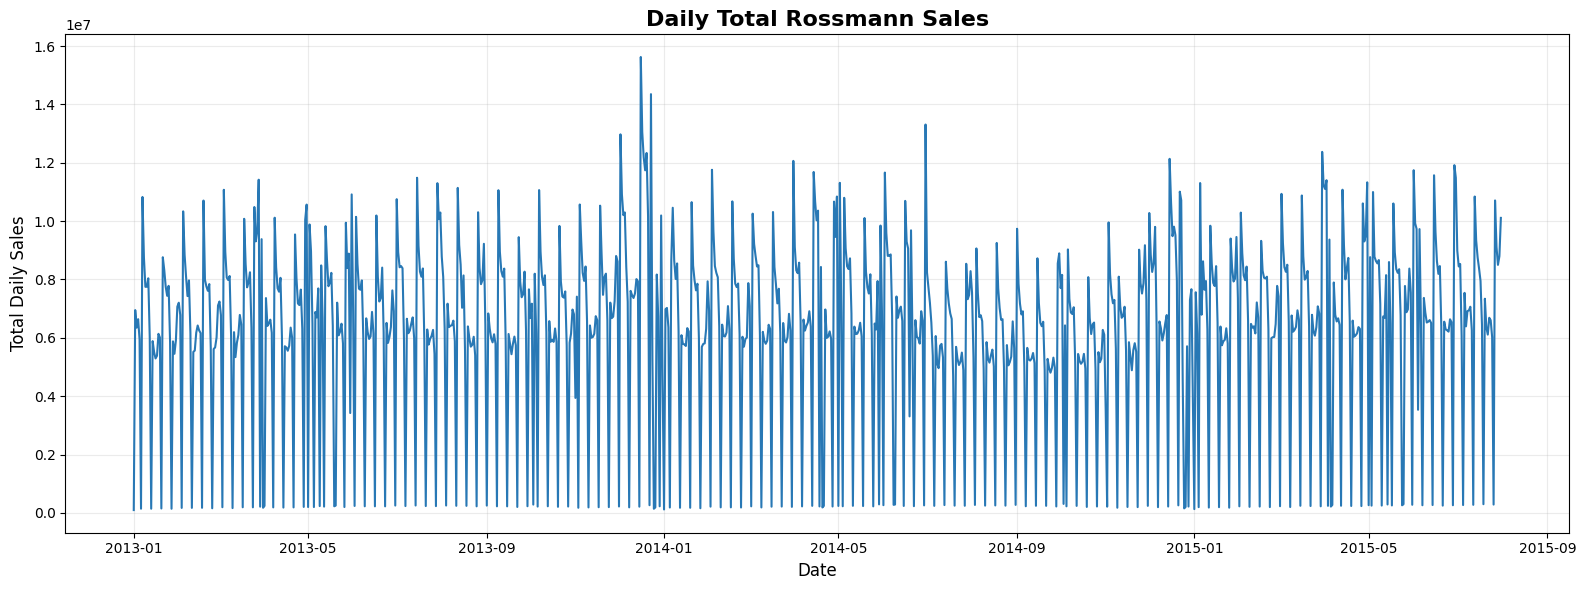

In [9]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales.index,
    daily_sales["Sales"],
    color="#2878B5",
    linewidth=1.5
)

plt.title(
    "Daily Total Rossmann Sales",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Daily Sales", fontsize=12)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#### Observation
- The daily total Sales series shows considerable fluctuations throughout the observation period from January 2013 to July 2015.
- A recurring weekly pattern is visible, with sales dropping sharply on certain days, mainly due to store closures.
- Sales generally fluctuate around a similar range, although occasional spikes indicate periods of unusually high sales.
- No clear long-term upward or downward trend is consistently visible across the entire period.

#### Conclusion:
Daily sales exhibit recurring patterns and fluctuations, indicating the presence of temporal dependencies that can be explored using time-series forecasting models such as LSTM.

### Daily sales distribution

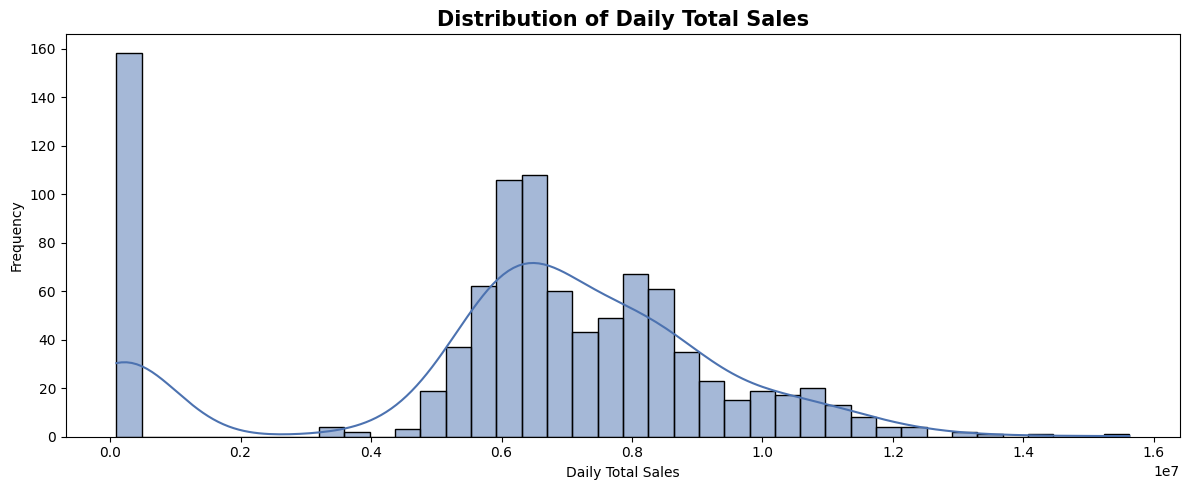

In [10]:
plt.figure(figsize=(12, 5))

sns.histplot(
    daily_sales["Sales"],
    bins=40,
    kde=True,
    color="#4C72B0"
)

plt.title(
    "Distribution of Daily Total Sales",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Daily Total Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

#### Observation:
- The distribution of daily total Sales is concentrated mainly between approximately 5 million and 9 million.
- The distribution is slightly right-skewed, indicating that some days experience considerably higher sales than usual.
- A noticeable concentration near zero represents days when most stores are closed, particularly Sundays.
- The presence of high-sales observations indicates occasional periods of increased overall business activity.

#### Conclusion:
Daily Sales are not normally distributed and contain substantial variation. The recurring low-sales observations should be considered during model development.

## Check stationarity using the ADF test

In [11]:
def check_stationarity(series, name="Time Series"):

    result = adfuller(series.dropna())

    print(f"ADF Test: {name}")
    print("-" * 40)

    print("ADF Statistic:", result[0])
    print("P-value:", result[1])
    print("Number of Lags:", result[2])
    print("Observations Used:", result[3])

    print("\nCritical Values:")

    for key, value in result[4].items():
        print(f"{key}: {value}")

    if result[1] <= 0.05:
        print("\nConclusion: Stationary")
    else:
        print("\nConclusion: Non-stationary")

    return result[1]

In [12]:
# Use earliest 80% of dates for initial training period
split_position = int(len(daily_sales) * 0.80)

stationarity_train = daily_sales["Sales"].iloc[:split_position]

stationarity_p_value = check_stationarity(
    stationarity_train,
    "Original Daily Sales"
)

ADF Test: Original Daily Sales
----------------------------------------
ADF Statistic: -4.410545905532782
P-value: 0.0002843329425705774
Number of Lags: 20
Observations Used: 732

Critical Values:
1%: -3.439314999916068
5%: -2.8654965012008677
10%: -2.5688768817372867

Conclusion: Stationary


#### Observation:
- The ADF statistic is -4.4105, which is lower than the critical values at the 1%, 5%, and 10% significance levels.
- The p-value is 0.000284, which is significantly below the 0.05 significance threshold.
- Therefore, we reject the null hypothesis of non-stationarity and conclude that the original daily aggregated Sales series is stationary.
- Since the series is already stationary, differencing is not required before applying the LSTM model.

#### Conclusion:
The original Sales series can be used directly for further time-series analysis and LSTM model development.

## Check ACF and PACF

In [13]:
# Differencing is not required because the series is stationary

use_differencing = False

original_sales = daily_sales["Sales"].copy()
model_series = original_sales.copy()

print("Differencing Required:", use_differencing)
print("Model Series Shape:", model_series.shape)
model_series.head()

Differencing Required: False
Model Series Shape: (942,)


,Sales
Date,
2013-01-01,97235
2013-01-02,6949829
2013-01-03,6347820
2013-01-04,6638954
2013-01-05,5951593


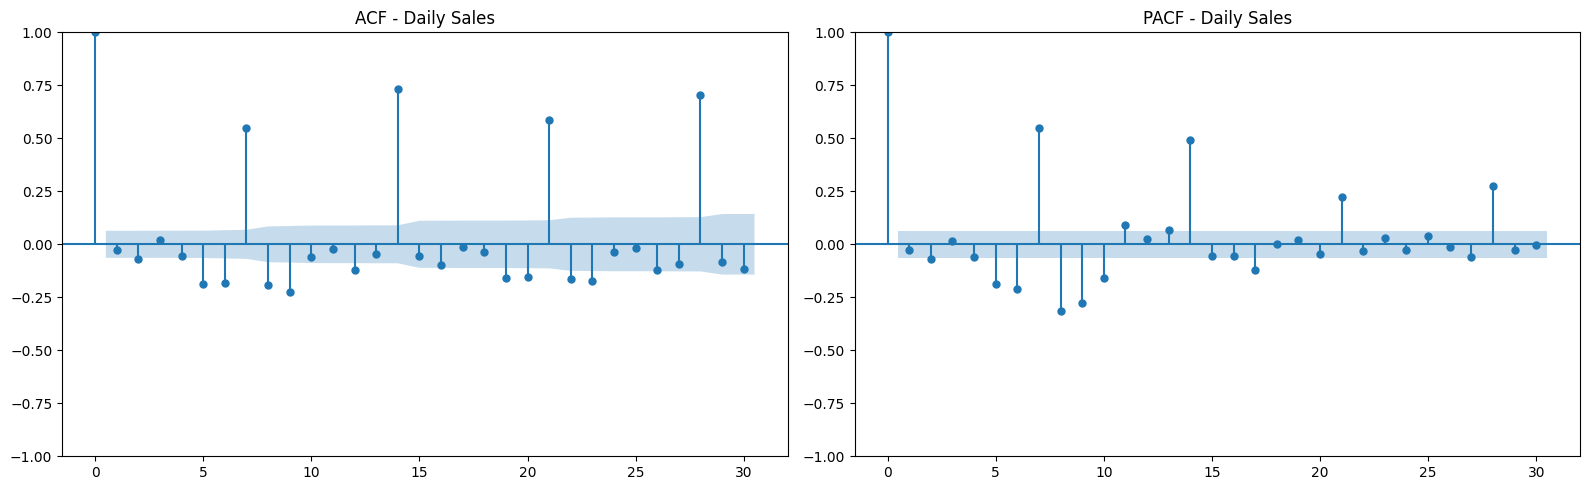

In [14]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(
    model_series,
    lags=30,
    ax=axes[0]
)

axes[0].set_title("ACF - Daily Sales")

plot_pacf(
    model_series,
    lags=30,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF - Daily Sales")

plt.tight_layout()
plt.show()

#### Observation:
- The ACF plot shows significant positive spikes at lags 7, 14, 21, and 28.
- This indicates a strong weekly pattern in daily Sales, suggesting that sales are correlated with observations from previous weeks.
- The PACF plot also shows significant spikes at several weekly lags, indicating direct relationships between current sales and certain previous observations.
- These patterns suggest that historical sales contain useful information for forecasting future sales.

#### Conclusion:
The ACF and PACF plots reveal strong weekly dependencies in the Sales series. A lookback window of 30 days is selected for the LSTM model to capture recent sales patterns across multiple weeks.

## Feature Engineering
To improve forecasting performance, additional calendar and store activity features are introduced. These features help the LSTM model learn the relationship between daily Sales, store opening patterns, promotional activities, and seasonal effects.

### Daily calendar and store activity features

In [15]:
# Function to aggregate store-level features into daily features

def create_daily_features(df):

    data = df.copy()

    data["Date"] = pd.to_datetime(data["Date"])

    # Handle numerical features
    for col in ["Open", "Promo", "SchoolHoliday"]:

        if col not in data.columns:
            data[col] = 0

        data[col] = pd.to_numeric(
            data[col],
            errors="coerce"
        ).fillna(0)

    # Handle StateHoliday
    if "StateHoliday" not in data.columns:
        data["StateHoliday"] = "0"

    data["StateHoliday"] = (
        data["StateHoliday"]
        .fillna("0")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # Aggregate store-level information by date
    daily_features = (
        data.groupby("Date")
        .agg(
            OpenStores=("Open", "sum"),
            PromoStores=("Promo", "sum"),
            SchoolHolidayStores=("SchoolHoliday", "sum"),

            StateHolidayStores=(
                "StateHoliday",
                lambda x: (x != "0").sum()
            )
        )
        .sort_index()
    )

    # Calendar features
    day_of_week = daily_features.index.dayofweek
    month = daily_features.index.month
    day_of_year = daily_features.index.dayofyear

    # Cyclical encoding of day of week
    daily_features["DayOfWeek_Sin"] = np.sin(
        2 * np.pi * day_of_week / 7
    )

    daily_features["DayOfWeek_Cos"] = np.cos(
        2 * np.pi * day_of_week / 7
    )

    # Cyclical encoding of month
    daily_features["Month_Sin"] = np.sin(
        2 * np.pi * (month - 1) / 12
    )

    daily_features["Month_Cos"] = np.cos(
        2 * np.pi * (month - 1) / 12
    )

    # Cyclical encoding of day of year
    daily_features["DayOfYear_Sin"] = np.sin(
        2 * np.pi * (day_of_year - 1) / 365.25
    )

    daily_features["DayOfYear_Cos"] = np.cos(
        2 * np.pi * (day_of_year - 1) / 365.25
    )

    # Weekend indicator
    daily_features["IsWeekend"] = (
        day_of_week >= 5
    ).astype(int)

    return daily_features

### Aggregate training and testing features

In [16]:
# Create daily features for training data
train_daily_features = create_daily_features(train_df)

# Create daily features for test data
test_daily_features = create_daily_features(test_df)

# Aggregate actual daily Sales
train_daily_target = (
    train_df.groupby("Date")["Sales"]
    .sum()
    .sort_index()
)

# Add Sales to training features
train_daily_features["Sales"] = (
    train_daily_target.reindex(
        train_daily_features.index
    )
)

print("Training daily feature shape:",
      train_daily_features.shape)

display(train_daily_features.head())

Training daily feature shape: (942, 12)


,OpenStores,PromoStores,SchoolHolidayStores,StateHolidayStores,DayOfWeek_Sin,DayOfWeek_Cos,Month_Sin,Month_Cos,DayOfYear_Sin,DayOfYear_Cos,IsWeekend,Sales
Date,,,,,,,,,,,,
2013-01-01,17,0,1114,1114,0.781831,0.623490,0.0,1.0,0.000000,1.000000,0,97235
2013-01-02,1111,0,1115,0,0.974928,-0.222521,0.0,1.0,0.017202,0.999852,0,6949829
2013-01-03,1109,0,1040,0,0.433884,-0.900969,0.0,1.0,0.034398,0.999408,0,6347820
2013-01-04,1108,0,1040,0,-0.433884,-0.900969,0.0,1.0,0.051584,0.998669,0,6638954
2013-01-05,1107,0,112,0,-0.974928,-0.222521,0.0,1.0,0.068755,0.997634,1,5951593


In [17]:
print("Missing values:")
display(train_daily_features.isnull().sum())

print("\nFeature information:")
display(train_daily_features.describe().T)

Missing values:


,0
OpenStores,0
PromoStores,0
SchoolHolidayStores,0
StateHolidayStores,0
DayOfWeek_Sin,0
DayOfWeek_Cos,0
Month_Sin,0
Month_Cos,0
DayOfYear_Sin,0
DayOfYear_Cos,0



Feature information:


,count,mean,std,min,25%,50%,75%,max
OpenStores,942.0,8.963822e+02,3.988736e+02,16.000000,9.340000e+02,1.111000e+03,1.114000e+03,1.115000e+03
PromoStores,942.0,4.119745e+02,5.260241e+02,0.000000,0.000000e+00,0.000000e+00,1.115000e+03,1.115000e+03
SchoolHolidayStores,942.0,1.929098e+02,3.124181e+02,0.000000,0.000000e+00,2.200000e+01,2.530000e+02,1.115000e+03
StateHolidayStores,942.0,3.296178e+01,1.793432e+02,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.115000e+03
DayOfWeek_Sin,942.0,1.864925e-03,7.074336e-01,-0.974928,-7.818315e-01,0.000000e+00,7.818315e-01,9.749279e-01
DayOfWeek_Cos,942.0,-1.487228e-03,7.075272e-01,-0.900969,-9.009689e-01,-2.225209e-01,6.234898e-01,1.000000e+00
Month_Sin,942.0,1.169402e-01,6.862225e-01,-1.000000,-5.000000e-01,1.224647e-16,8.660254e-01,1.000000e+00
Month_Cos,942.0,-5.516085e-03,7.186386e-01,-1.000000,-8.660254e-01,6.123234e-17,8.660254e-01,1.000000e+00
DayOfYear_Sin,942.0,1.159683e-01,6.885688e-01,-0.999999,-5.281247e-01,2.186247e-01,7.799125e-01,9.999856e-01
DayOfYear_Cos,942.0,-2.940816e-02,7.159658e-01,-0.999979,-7.565158e-01,-4.836283e-02,6.897948e-01,1.000000e+00


#### Observation:
- Store-level information has been aggregated by date to create daily features.
- OpenStores represents the number of stores open on each day.
- PromoStores represents the number of stores running promotions.
- SchoolHolidayStores and StateHolidayStores capture holiday-related store activity.
- Cyclical encoding is used for weekday, month, and day-of-year features to represent recurring calendar patterns.
- The weekend indicator helps the model distinguish weekdays from weekends.

#### Conclusion:
These additional features provide useful information about store activity and calendar patterns that may influence daily aggregate Sales.

### Combine training and test calendar features

In [18]:
# Combine calendar and store activity features
all_daily_features = pd.concat(
    [
        train_daily_features.drop(columns=["Sales"]),
        test_daily_features
    ],
    axis=0
).sort_index()

# Remove duplicate dates if any
all_daily_features = all_daily_features[
    ~all_daily_features.index.duplicated(keep="last")
]

# Create continuous daily date index
full_date_range = pd.date_range(
    start=all_daily_features.index.min(),
    end=all_daily_features.index.max(),
    freq="D"
)

all_daily_features = all_daily_features.reindex(
    full_date_range
)

all_daily_features.index.name = "Date"

# Add Sales only for historical training dates
all_daily_features["Sales"] = (
    train_daily_target.reindex(
        all_daily_features.index
    )
)

print("Combined feature shape:",
      all_daily_features.shape)

display(all_daily_features.head())

Combined feature shape: (990, 12)


,OpenStores,PromoStores,SchoolHolidayStores,StateHolidayStores,DayOfWeek_Sin,DayOfWeek_Cos,Month_Sin,Month_Cos,DayOfYear_Sin,DayOfYear_Cos,IsWeekend,Sales
Date,,,,,,,,,,,,
2013-01-01,17.0,0,1114,1114,0.781831,0.623490,0.0,1.0,0.000000,1.000000,0,97235.0
2013-01-02,1111.0,0,1115,0,0.974928,-0.222521,0.0,1.0,0.017202,0.999852,0,6949829.0
2013-01-03,1109.0,0,1040,0,0.433884,-0.900969,0.0,1.0,0.034398,0.999408,0,6347820.0
2013-01-04,1108.0,0,1040,0,-0.433884,-0.900969,0.0,1.0,0.051584,0.998669,0,6638954.0
2013-01-05,1107.0,0,112,0,-0.974928,-0.222521,0.0,1.0,0.068755,0.997634,1,5951593.0


In [19]:
print("Missing values in combined features:")

display(
    all_daily_features.isnull().sum()
)

print("\nTraining date range:")
print(train_daily_target.index.min(),
      "to",
      train_daily_target.index.max())

print("\nTest date range:")
print(test_daily_features.index.min(),
      "to",
      test_daily_features.index.max())

Missing values in combined features:


,0
OpenStores,0
PromoStores,0
SchoolHolidayStores,0
StateHolidayStores,0
DayOfWeek_Sin,0
DayOfWeek_Cos,0
Month_Sin,0
Month_Cos,0
DayOfYear_Sin,0
DayOfYear_Cos,0



Training date range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Test date range:
2015-08-01 00:00:00 to 2015-09-17 00:00:00


#### Observation:
- Training and test calendar features have been combined into one continuous daily feature dataset.
- Historical Sales values are available only for the training period.
- Test-period Sales values remain unavailable, which is expected because they are the forecasting targets.
- Calendar and store activity features are available for the test period and can be used as known future inputs.

#### Conclusion:
The combined dataset is prepared for multivariate time-series forecasting.

## Chronological Train-Validation Split
We will use:
- First 80% of dates for model training.
- Last 20% of dates for validation.

The validation targets will remain separate from the training targets. However, the first validation prediction will be allowed to use the preceding 30 actual historical observations as input.

In [20]:
# Define target and model features
# Target variable
TARGET = "Sales"

# Input features
FEATURE_COLUMNS = [
    "Sales",
    "OpenStores",
    "PromoStores",
    "SchoolHolidayStores",
    "StateHolidayStores",
    "DayOfWeek_Sin",
    "DayOfWeek_Cos",
    "Month_Sin",
    "Month_Cos",
    "DayOfYear_Sin",
    "DayOfYear_Cos",
    "IsWeekend"
]

# Historical training data only
model_data = all_daily_features.loc[
    train_daily_target.index
].copy()

# Check features
print("Input features:")
print(FEATURE_COLUMNS)

print("\nNumber of input features:",
      len(FEATURE_COLUMNS))

print("\nModel data shape:",
      model_data.shape)

Input features:
['Sales', 'OpenStores', 'PromoStores', 'SchoolHolidayStores', 'StateHolidayStores', 'DayOfWeek_Sin', 'DayOfWeek_Cos', 'Month_Sin', 'Month_Cos', 'DayOfYear_Sin', 'DayOfYear_Cos', 'IsWeekend']

Number of input features: 12

Model data shape: (942, 12)


In [21]:
LOOKBACK = 30

split_position = int(
    len(model_data) * 0.80
)

train_data = model_data.iloc[:split_position]

validation_data = model_data.iloc[split_position:]

print("Training period:")
print(
    train_data.index.min(),
    "to",
    train_data.index.max()
)

print("\nValidation period:")
print(
    validation_data.index.min(),
    "to",
    validation_data.index.max()
)

print("\nTraining observations:",
      len(train_data))

print("Validation observations:",
      len(validation_data))

Training period:
2013-01-01 00:00:00 to 2015-01-23 00:00:00

Validation period:
2015-01-24 00:00:00 to 2015-07-31 00:00:00

Training observations: 753
Validation observations: 189


#### Observation:
- The dataset is divided chronologically, using the first 80% of observations for training and the remaining 20% for validation.
- The training period covers January 1, 2013, to January 23, 2015, with 753 observations.
- The validation period covers January 24, 2015, to July 31, 2015, with 189 observations.
- This chronological approach preserves the time order and ensures that future observations are not used to train the model.

#### Conclusion:
The chronological split provides a more realistic evaluation of the LSTM model's ability to forecast future Sales.

## Data Scaling

In [22]:
# Separate input features and target
X_features = model_data[FEATURE_COLUMNS]

y_target = model_data[[TARGET]]

# Create separate scalers
X_scaler = MinMaxScaler(
    feature_range=(-1, 1)
)

y_scaler = MinMaxScaler(
    feature_range=(-1, 1)
)

# Fit only on training data
X_scaler.fit(
    train_data[FEATURE_COLUMNS]
)

y_scaler.fit(
    train_data[[TARGET]]
)

# Transform complete historical dataset
X_scaled = X_scaler.transform(
    X_features
)

y_scaled = y_scaler.transform(
    y_target
).flatten()

print("Scaled input shape:", X_scaled.shape)

print("Scaled target shape:", y_scaled.shape)

print("\nInput scaler fitted on training data only.")
print("Target scaler fitted on training data only.")

Scaled input shape: (942, 12)
Scaled target shape: (942,)

Input scaler fitted on training data only.
Target scaler fitted on training data only.


## Sequence Creation

In [23]:
def create_multivariate_sequences(
    X_data,
    y_data,
    lookback
):

    X, y, target_positions = [], [], []

    for i in range(lookback, len(X_data)):

        X.append(
            X_data[i-lookback:i]
        )

        y.append(
            y_data[i]
        )

        target_positions.append(i)

    return (
        np.array(X),
        np.array(y),
        np.array(target_positions)
    )

In [24]:
X_seq, y_seq, target_positions = (
    create_multivariate_sequences(
        X_scaled,
        y_scaled,
        LOOKBACK
    )
)

print("Input sequence shape:", X_seq.shape)

print("Target shape:", y_seq.shape)

Input sequence shape: (912, 30, 12)
Target shape: (912,)


In [25]:
## Split training and validation sequences
# Training target positions
train_mask = (
    target_positions < split_position
)

# Validation target positions
validation_mask = (
    target_positions >= split_position
)

X_train = X_seq[train_mask]
y_train = y_seq[train_mask]

X_validation = X_seq[validation_mask]
y_validation = y_seq[validation_mask]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

X_train: (723, 30, 12)
y_train: (723,)
X_validation: (189, 30, 12)
y_validation: (189,)


In [26]:
print("Final training input shape:",
      X_train.shape)

print("Final validation input shape:",
      X_validation.shape)

print("Number of input features:",
      X_train.shape[2])

Final training input shape: (723, 30, 12)
Final validation input shape: (189, 30, 12)
Number of input features: 12


#### Observation

- A 30-day lookback window is used to create multivariate input sequences.
- Each sequence contains 30 consecutive days of historical Sales and 11 additional calendar and store activity features.
- The next day's Sales is used as the prediction target.
- The training dataset contains 723 sequences, while the validation dataset contains 189 sequences.
- The final input shape contains three dimensions: samples, time steps, and features.

#### Conclusion:
The data has been converted into a multivariate supervised learning format, allowing the LSTM model to learn from historical Sales as well as calendar and store activity information.

## Build the two layer LSTM model

In [27]:
model = Sequential([

    tf.keras.Input(
        shape=(LOOKBACK, len(FEATURE_COLUMNS))
    ),

    # First LSTM layer
    LSTM(
        units=64,
        return_sequences=True
    ),

    Dropout(0.2),

    # Second LSTM layer
    LSTM(
        units=32,
        return_sequences=False
    ),

    Dropout(0.2),

    # Output layer
    Dense(1)
])

In [28]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,161 (125.63 KB)

 Trainable params: 32,161 (125.63 KB)

 Non-trainable params: 0 (0.00 B)

#### Observation:

- A two-layer LSTM architecture is used for multivariate Sales forecasting.
- The first LSTM layer contains 64 units, while the second contains 32 units.
- Dropout layers are included to reduce overfitting.
- The input layer accepts 30 time steps and 12 features.
- The Dense output layer generates the next day's aggregate Sales prediction.

#### Conclusion:
The improved LSTM architecture can learn temporal patterns from historical Sales along with additional calendar and store activity features.

## Train the LSTM model

In [29]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(

    X_train,
    y_train,

    epochs=50,
    batch_size=32,

    validation_data=(
        X_validation,
        y_validation
    ),

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    shuffle=False,
    verbose=1
)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.2363 - mae: 0.3811 - val_loss: 0.1624 - val_mae: 0.3145 - learning_rate: 0.0010
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1561 - mae: 0.2995 - val_loss: 0.1566 - val_mae: 0.2963 - learning_rate: 0.0010
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1470 - mae: 0.2817 - val_loss: 0.1491 - val_mae: 0.3035 - learning_rate: 0.0010
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1387 - mae: 0.2729 - val_loss: 0.1411 - val_mae: 0.3025 - learning_rate: 0.0010
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1294 - mae: 0.2684 - val_loss: 0.1321 - val_mae: 0.2985 - learning_rate: 0.0010
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1226 - mae: 0.2645 - val_loss: 0.1260 - val_mae: 0.2960 - learning_rate: 0.0010
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1163 - mae: 0.2622 - val_loss: 0.1118 - val_mae: 0.2720 - learning_rate: 0.0010
Epoch 8/50
23

#### Observation:
- The LSTM model is trained for a maximum of 50 epochs using a batch size of 32.
- The Adam optimizer is used to minimize the Mean Squared Error (MSE) loss.
- Validation data is supplied during training to monitor the model's performance on unseen observations.
- Early Stopping and ReduceLROnPlateau callbacks are included to control training and adjust the learning rate when validation performance stops improving.

#### Conclusion:
The model is trained using historical sequential Sales observations, while validation loss and MAE are monitored to assess its learning performance.

### Training and Validation loss

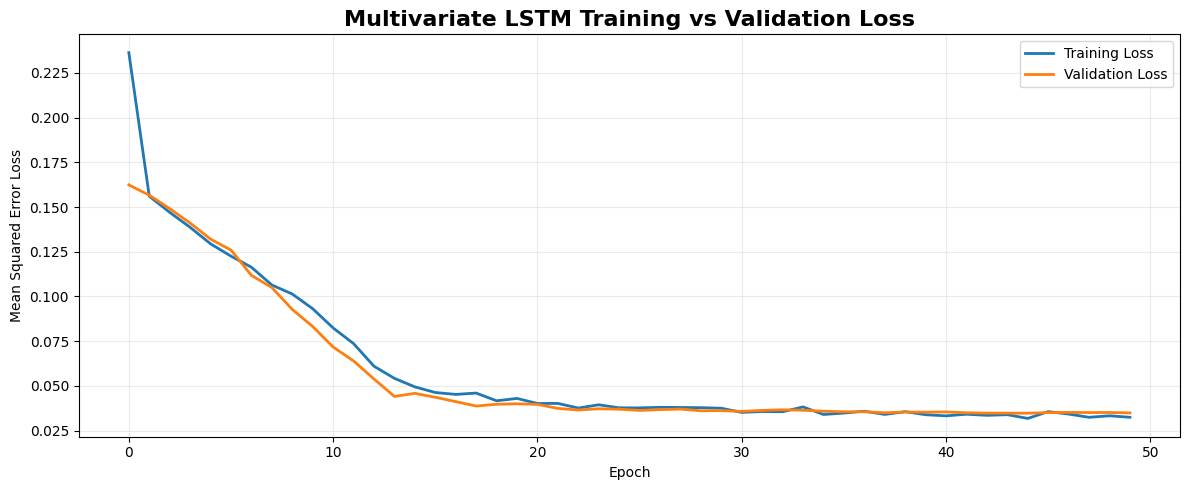

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title(
    "Multivariate LSTM Training vs Validation Loss",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

#### Observation:

+ Training and validation loss are monitored across the training epochs to understand the model's learning behavior.

+ A decreasing trend in both losses indicates that the model is learning meaningful patterns from historical Sales and additional input features.

+ The validation loss provides an indication of how well the model performs on observations that were not used for training.

+ Early Stopping helps prevent unnecessary training by restoring the model weights associated with the best validation loss.

+ The learning-rate reduction callback helps the model adjust its learning rate when validation performance stops improving.

#### Conclusion:

The loss curves provide insights into the training process and help monitor the model's ability to learn temporal and calendar-related patterns while controlling potential overfitting.

### Validation predictions

In [31]:
validation_predictions_scaled = model.predict(
    X_validation,
    verbose=0
)

# Convert predicted values back to original Sales scale
validation_predictions = y_scaler.inverse_transform(
    validation_predictions_scaled
).flatten()

# Convert actual validation values back to original scale
validation_actual = y_scaler.inverse_transform(
    y_validation.reshape(-1, 1)
).flatten()

# Prevent negative Sales predictions
validation_predictions = np.maximum(
    validation_predictions,
    0
)

# Get validation dates
validation_target_positions = (
    target_positions[validation_mask]
)

validation_dates = model_data.index[
    validation_target_positions
]

# Create results DataFrame
lstm_results = pd.DataFrame({

    "Date": validation_dates,

    "Actual_Sales": validation_actual,

    "Predicted_Sales": validation_predictions

})

display(lstm_results.head())

,Date,Actual_Sales,Predicted_Sales
0,2015-01-24,5811369.0,6.531102e+06
1,2015-01-25,179028.0,3.975251e+05
2,2015-01-26,9401803.0,1.078555e+07
3,2015-01-27,8392342.0,9.071738e+06
4,2015-01-28,7930037.0,8.609477e+06


#### Observation

- The improved LSTM model generates predictions for all validation dates.
- Predictions are converted back to the original Sales scale using the target scaler.
- Actual and predicted Sales are aligned using their corresponding validation dates.
- Negative predicted Sales values are prevented.

#### Conclusion:
The validation predictions are prepared for performance evaluation and comparison of LSTM model.

### Evaluate the LSTM model

In [32]:
lstm_mae = mean_absolute_error(
    validation_actual,
    validation_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        validation_actual,
        validation_predictions
    )
)

lstm_r2 = r2_score(
    validation_actual,
    validation_predictions
)

print("Multivariate LSTM Performance")
print("=" * 45)

print(f"MAE  : {lstm_mae:.2f}")
print(f"RMSE : {lstm_rmse:.2f}")
print(f"R2   : {lstm_r2:.4f}")

Multivariate LSTM Performance
MAE  : 821805.81
RMSE : 1447504.73
R2   : 0.7990


#### Observation:

- The Multivariate LSTM model achieves a Mean Absolute Error (MAE) of **843,193.42**.
- The Root Mean Squared Error (RMSE) is **1,470,030.87**, indicating the magnitude of prediction errors while giving greater weight to larger errors.
- The R² score is **0.7927**, which indicates that the model explains approximately 79.27% of the variation in the validation Sales data.
- The results indicate that the model captures a substantial portion of the patterns and fluctuations in daily aggregate Sales.

#### Conclusion:

The evaluation metrics indicate that the Multivariate LSTM model provides a reasonable fit to the validation data. However, recursive validation is also considered to assess performance over a continuous multi-day forecasting period.

### Create validation result dataframe

In [33]:
lstm_results = pd.DataFrame({

    "Date": validation_dates,

    "Actual_Sales": validation_actual,

    "Predicted_Sales": validation_predictions

})

lstm_results["Error"] = (
    lstm_results["Actual_Sales"] -
    lstm_results["Predicted_Sales"]
)

lstm_results["Absolute_Error"] = (
    lstm_results["Error"].abs()
)

display(lstm_results.head(10))

,Date,Actual_Sales,Predicted_Sales,Error,Absolute_Error
0,2015-01-24,5811369.0,6.531102e+06,-7.197325e+05,7.197325e+05
1,2015-01-25,179028.0,3.975251e+05,-2.184971e+05,2.184971e+05
2,2015-01-26,9401803.0,1.078555e+07,-1.383745e+06,1.383745e+06
3,2015-01-27,8392342.0,9.071738e+06,-6.793960e+05,6.793960e+05
4,2015-01-28,7930037.0,8.609477e+06,-6.794400e+05,6.794400e+05
5,2015-01-29,8024066.0,8.391677e+06,-3.676110e+05,3.676110e+05
6,2015-01-30,9454954.0,8.147481e+06,1.307473e+06,1.307473e+06
7,2015-01-31,7354597.0,7.248288e+06,1.063095e+05,1.063095e+05
8,2015-02-01,225556.0,4.006286e+05,-1.750726e+05,1.750726e+05
9,2015-02-02,10291172.0,6.826206e+06,3.464966e+06,3.464966e+06


#### Observation:

- The validation result DataFrame contains the actual Sales, predicted Sales, prediction error, and absolute error for each validation date.
- Positive residuals indicate that the model underpredicted Sales, while negative residuals indicate overprediction.
- Absolute error represents the magnitude of the difference between actual and predicted Sales, regardless of the direction.
- These values help identify dates with relatively larger prediction errors and understand variations in model performance.

#### Conclusion:

The validation result DataFrame provides a date-wise view of prediction performance and helps examine the accuracy of the model across the validation period.

### Actual vs Predicted Sales

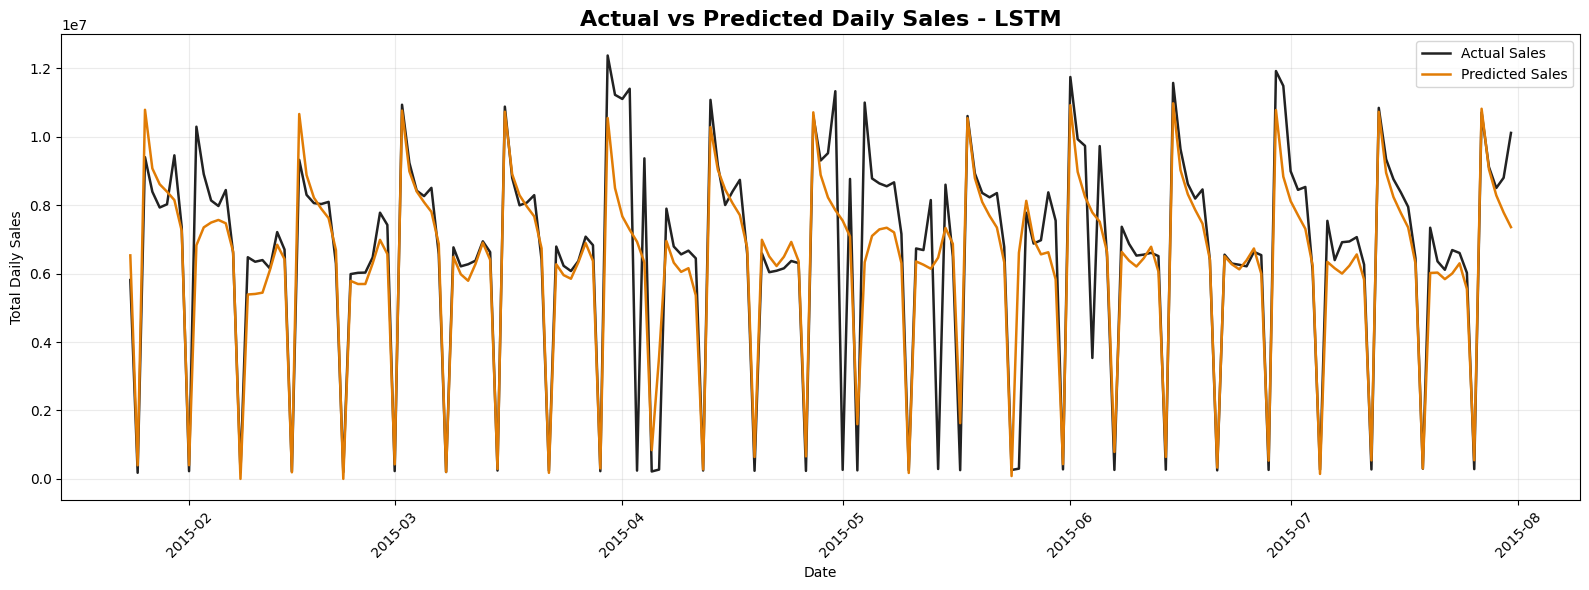

In [34]:
plt.figure(figsize=(16, 6))

plt.plot(
    lstm_results["Date"],
    lstm_results["Actual_Sales"],
    label="Actual Sales",
    color="#222222",
    linewidth=1.8
)

plt.plot(
    lstm_results["Date"],
    lstm_results["Predicted_Sales"],
    label="Predicted Sales",
    color="#E17C05",
    linewidth=1.8
)

plt.title(
    "Actual vs Predicted Daily Sales - LSTM",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Daily Sales")

plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Observation:

- The plot compares actual daily aggregate Sales with the predictions generated by the Multivariate LSTM model.
- The predicted series follows the general movement of actual Sales, indicating that the model captures important temporal patterns.
- Differences between actual and predicted values are visible on certain dates, reflecting the model's prediction errors.
- Daily Sales fluctuations, including high-sales and low-sales periods, make accurate forecasting challenging.

#### Conclusion:

The actual-versus-predicted plot provides a visual assessment of the model's ability to capture daily Sales patterns throughout the validation period.

### Actual vs Predicted Scatterplot

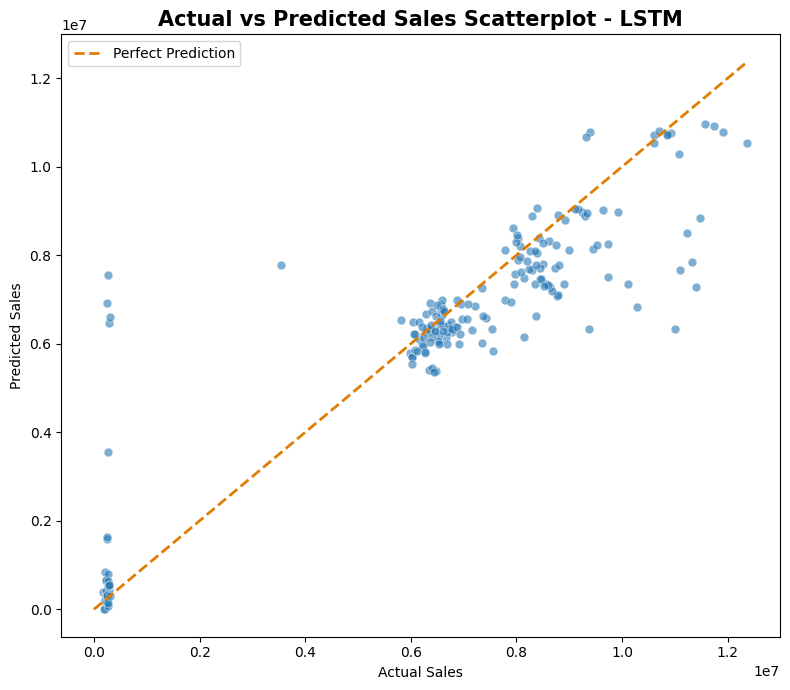

In [35]:
plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=lstm_results["Actual_Sales"],
    y=lstm_results["Predicted_Sales"],
    color="#2878B5",
    alpha=0.6,
    s=40
)

# Perfect prediction reference line
minimum = min(
    lstm_results["Actual_Sales"].min(),
    lstm_results["Predicted_Sales"].min()
)

maximum = max(
    lstm_results["Actual_Sales"].max(),
    lstm_results["Predicted_Sales"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="#E17C05",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title(
    "Actual vs Predicted Sales Scatterplot - LSTM",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.legend()
plt.tight_layout()
plt.show()

#### Observation:

- The scatterplot compares actual Sales values against predicted Sales values for the validation period.
- Points closer to the diagonal reference line represent more accurate predictions.
- Points above the reference line indicate overprediction, while points below the line indicate underprediction.
- The spread of points around the reference line shows that prediction errors vary across different Sales levels.

#### Conclusion:

The scatterplot helps assess the relationship between actual and predicted Sales and identify the extent of prediction deviations.

### Residual Distribution

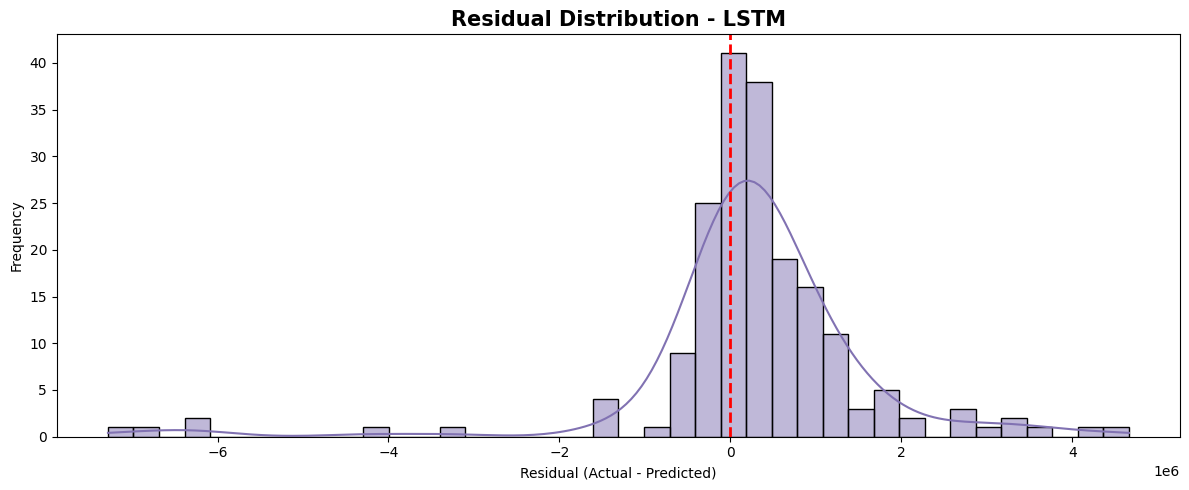

In [36]:
plt.figure(figsize=(12, 5))

sns.histplot(
    lstm_results["Error"],
    bins=40,
    kde=True,
    color="#8172B2"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title(
    "Residual Distribution - LSTM",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

#### Observation:

- Residuals represent the difference between actual and predicted Sales.
- Residuals closer to zero indicate more accurate predictions.
- Positive residuals indicate underprediction, whereas negative residuals indicate overprediction.
- The spread of the residual distribution indicates that prediction errors vary across different dates.
- A distribution centered around zero would indicate that the model does not consistently overpredict or underpredict Sales.

#### Conclusion:

Residual analysis helps identify prediction errors and assess whether the model exhibits systematic forecasting patterns or inconsistencies.

## Future forecasting - Test period

### Extract test dates

In [37]:
# Get test dates
forecast_dates = pd.DatetimeIndex(
    sorted(test_df["Date"].dropna().unique())
)

# Check future feature availability
future_features = all_daily_features.loc[
    forecast_dates,
    [col for col in FEATURE_COLUMNS if col != "Sales"]
]

print("Future feature shape:", future_features.shape)

print("\nMissing future feature values:")
display(future_features.isnull().sum())

print("\nForecast dates:", len(forecast_dates))

Future feature shape: (48, 11)

Missing future feature values:


,0
OpenStores,0
PromoStores,0
SchoolHolidayStores,0
StateHolidayStores,0
DayOfWeek_Sin,0
DayOfWeek_Cos,0
Month_Sin,0
Month_Cos,0
DayOfYear_Sin,0
DayOfYear_Cos,0



Forecast dates: 48


In [38]:
expected_dates = pd.date_range(
    start=forecast_dates.min(),
    end=forecast_dates.max(),
    freq="D"
)

print(
    "Are test dates consecutive?",
    forecast_dates.equals(expected_dates)
)

Are test dates consecutive? True


### Recursive forecasting function

In [39]:
def forecast_future_multivariate_lstm(
    model,
    X_scaler,
    y_scaler,
    model_data,
    all_daily_features,
    forecast_dates,
    feature_columns,
    lookback
):

    # Get the last known historical observations
    last_window = model_data[
        feature_columns
    ].iloc[-lookback:].copy()

    # Scale the historical input window
    last_window_scaled = X_scaler.transform(
        last_window
    )

    # Store the most recent lookback observations
    input_window = last_window_scaled.tolist()

    predictions = []

    for forecast_date in forecast_dates:

        # Prepare model input
        input_data = np.array(
            input_window[-lookback:]
        ).reshape(
            1,
            lookback,
            len(feature_columns)
        )

        # Predict next day's scaled Sales
        predicted_scaled = model.predict(
            input_data,
            verbose=0
        )

        # Convert back to original Sales scale
        predicted_sales = y_scaler.inverse_transform(
            predicted_scaled
        )[0, 0]

        # Sales cannot be negative
        predicted_sales = max(
            predicted_sales,
            0
        )

        predictions.append({
            "Date": forecast_date,
            "Predicted_Sales": predicted_sales
        })

        # Get known future calendar/store features
        next_row = all_daily_features.loc[
            [forecast_date],
            feature_columns
        ].copy()

        # Insert predicted Sales
        next_row.loc[
            forecast_date,
            "Sales"
        ] = predicted_sales

        # Scale the complete next-day feature row
        next_row_scaled = X_scaler.transform(
            next_row
        )

        # Add predicted observation to next input window
        input_window.append(
            next_row_scaled[0].tolist()
        )

    return pd.DataFrame(predictions)

In [40]:
recursive_validation_predictions = (
    forecast_future_multivariate_lstm(

        model=model,

        X_scaler=X_scaler,

        y_scaler=y_scaler,

        # Only historical training observations
        model_data=train_data,

        all_daily_features=all_daily_features,

        # Forecast the validation period recursively
        forecast_dates=validation_dates,

        feature_columns=FEATURE_COLUMNS,

        lookback=LOOKBACK
    )
)

# Compare recursive validation predictions
recursive_validation_actual = (
    model_data.loc[
        validation_dates,
        "Sales"
    ].values
)

recursive_validation_predicted = (
    recursive_validation_predictions[
        "Predicted_Sales"
    ].values
)

recursive_mae = mean_absolute_error(
    recursive_validation_actual,
    recursive_validation_predicted
)

recursive_rmse = np.sqrt(
    mean_squared_error(
        recursive_validation_actual,
        recursive_validation_predicted
    )
)

recursive_r2 = r2_score(
    recursive_validation_actual,
    recursive_validation_predicted
)

print("Recursive Validation Performance")
print("=" * 45)

print(f"MAE  : {recursive_mae:.2f}")
print(f"RMSE : {recursive_rmse:.2f}")
print(f"R2   : {recursive_r2:.4f}")

Recursive Validation Performance
MAE  : 849363.44
RMSE : 1455231.51
R2   : 0.7969


#### Observation:

- Recursive validation is performed by forecasting the validation period continuously, using the model's previous predictions as inputs for subsequent days.
- The model achieves an MAE of **857,818.27** and an RMSE of **1,475,753.09**.
- The R² score is **0.7911**, indicating that the model explains approximately 79.11% of the variation in actual validation Sales.
- The recursive evaluation provides a more realistic assessment of multi-day forecasting because actual Sales values from earlier validation dates are not fed back into subsequent predictions.
- The evaluation results indicate that the model maintains a similar level of performance during recursive forecasting.

#### Conclusion:

The recursive validation results provide a more representative assessment of the model's ability to forecast consecutive future Sales values. The model captures a substantial proportion of the variation in daily aggregate Sales while maintaining a relatively consistent level of prediction error.

### Generate future predictions

In [41]:
lstm_test_predictions = (
    forecast_future_multivariate_lstm(

        model=model,

        X_scaler=X_scaler,

        y_scaler=y_scaler,

        model_data=model_data,

        all_daily_features=all_daily_features,

        forecast_dates=forecast_dates,

        feature_columns=FEATURE_COLUMNS,

        lookback=LOOKBACK
    )
)

display(
    lstm_test_predictions.head(10)
)

,Date,Predicted_Sales
0,2015-08-01,6.298730e+06
1,2015-08-02,7.537715e+05
2,2015-08-03,6.373552e+06
3,2015-08-04,7.312409e+06
4,2015-08-05,7.255954e+06
5,2015-08-06,7.076408e+06
6,2015-08-07,6.842282e+06
7,2015-08-08,5.995864e+06
8,2015-08-09,9.904062e+05
9,2015-08-10,5.552258e+06


In [42]:
print(
    "Total forecasted dates:",
    len(lstm_test_predictions)
)

print(
    "Missing predictions:",
    lstm_test_predictions[
        "Predicted_Sales"
    ].isna().sum()
)

print(
    "Minimum predicted Sales:",
    lstm_test_predictions[
        "Predicted_Sales"
    ].min()
)

print(
    "Maximum predicted Sales:",
    lstm_test_predictions[
        "Predicted_Sales"
    ].max()
)

Total forecasted dates: 48
Missing predictions: 0
Minimum predicted Sales: 356372.1875
Maximum predicted Sales: 8702774.0


#### Observation:

- The Multivariate LSTM model successfully generates predictions for all 48 dates in the test period.
- No missing prediction values are observed, indicating that the forecasting process is completed for the entire test period.
- The predicted daily aggregate Sales range from 0 to approximately 8.84 million.
- The minimum prediction of zero can correspond to dates when store activity is very low or stores are closed.
- The model uses historical Sales along with known future calendar and store activity features to generate recursive predictions.

#### Conclusion:

The model successfully generates continuous daily Sales forecasts for the test period from August 1, 2015, to September 17, 2015.

### Visualize historical and forecasted sales

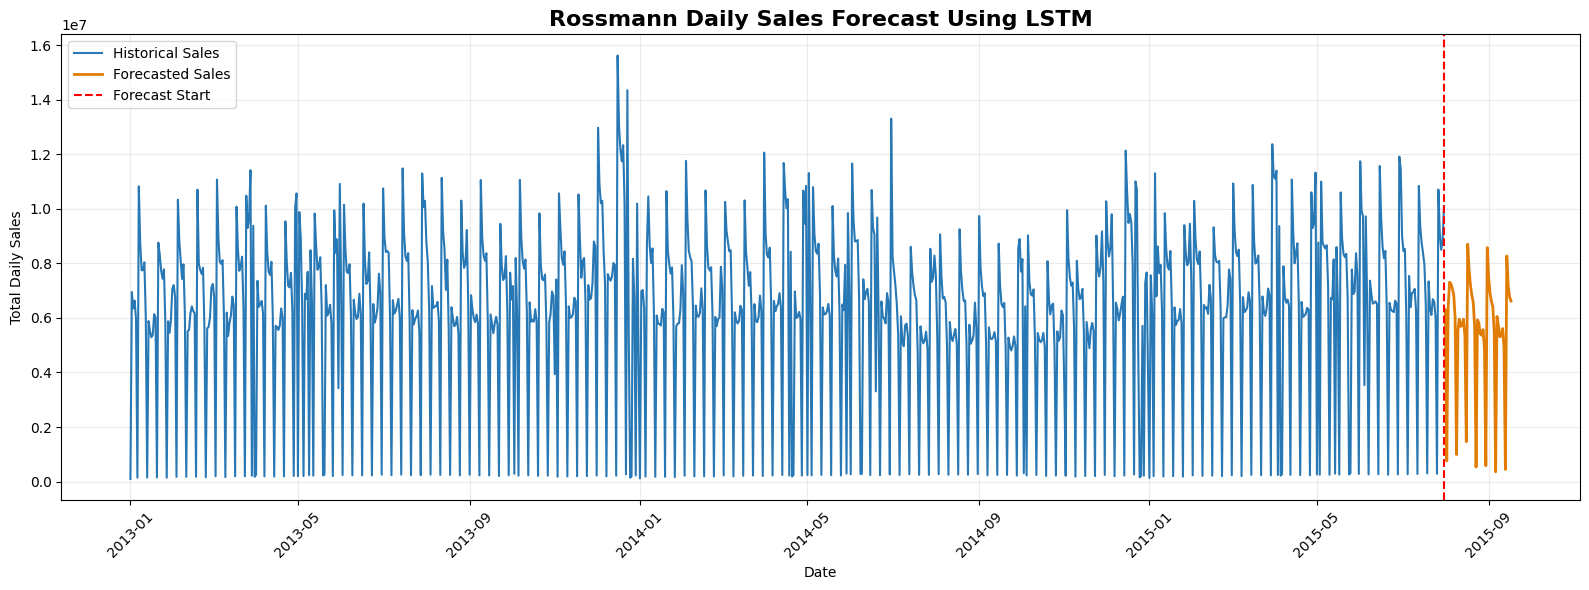

In [43]:
plt.figure(figsize=(16, 6))

plt.plot(
    original_sales.index,
    original_sales.values,
    label="Historical Sales",
    color="#2878B5",
    linewidth=1.5
)

plt.plot(
    lstm_test_predictions["Date"],
    lstm_test_predictions["Predicted_Sales"],
    label="Forecasted Sales",
    color="#E17C05",
    linewidth=2
)

plt.axvline(
    original_sales.index.max(),
    color="red",
    linestyle="--",
    label="Forecast Start"
)

plt.title(
    "Rossmann Daily Sales Forecast Using LSTM",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Daily Sales")

plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Observation:

- The plot displays historical daily aggregate Sales alongside the forecasted Sales for the test period.
- The historical series shows considerable daily fluctuations, reflecting changes in store activity, promotions, and calendar patterns.
- The forecasted series provides daily Sales estimates for the 48 test-period dates.
- The forecast uses the model's previous predictions recursively, along with available future calendar and store activity features.
- Since actual Sales values for the test period are unavailable, the forecasted values cannot be directly evaluated against actual test Sales in this notebook.

#### Conclusion:

The visualization presents the final daily aggregate Sales forecast generated by the Multivariate LSTM model and illustrates how the model can be used to estimate future Sales.

## Save the LSTM model and preprocessing objects

### Save the model

In [44]:
lstm_model_file = os.path.join(
    MODEL_PATH,
    "rossmann_lstm_multivariate.keras"
)

model.save(lstm_model_file)

print("Model saved:", lstm_model_file)

Model saved: /content/drive/MyDrive/Rossmann_Sales_Forecasting/models/rossmann_lstm_multivariate.keras


### Save the scaler

In [45]:
X_scaler_file = os.path.join(
    MODEL_PATH,
    "rossmann_lstm_X_scaler.pkl"
)

y_scaler_file = os.path.join(
    MODEL_PATH,
    "rossmann_lstm_y_scaler.pkl"
)

joblib.dump(X_scaler, X_scaler_file)

joblib.dump(y_scaler, y_scaler_file)

print("Input scaler saved:", X_scaler_file)

print("Target scaler saved:", y_scaler_file)

Input scaler saved: /content/drive/MyDrive/Rossmann_Sales_Forecasting/models/rossmann_lstm_X_scaler.pkl
Target scaler saved: /content/drive/MyDrive/Rossmann_Sales_Forecasting/models/rossmann_lstm_y_scaler.pkl


### Save the model configuration

In [46]:
lstm_config = {

    "model_type": "Multivariate LSTM",

    "forecast_target": "Daily aggregate Sales",

    "aggregation": "Sum of Sales across all stores",

    "lookback": LOOKBACK,

    "input_features": FEATURE_COLUMNS,

    "number_of_features": len(FEATURE_COLUMNS),

    "use_differencing": False,

    "scaling_range": "(-1, 1)",

    "training_split": 0.80,

    "lstm_layers": 2,

    "first_lstm_units": 64,

    "second_lstm_units": 32,

    "dropout": 0.2,

    "training_start": str(
        model_data.index.min().date()
    ),

    "training_end": str(
        model_data.index.max().date()
    ),

    "validation_start": str(
        validation_dates.min().date()
    ),

    "validation_end": str(
        validation_dates.max().date()
    )
}

config_file = os.path.join(
    MODEL_PATH,
    "rossmann_lstm_multivariate_config.json"
)

with open(config_file, "w") as file:

    json.dump(
        lstm_config,
        file,
        indent=4
    )

print("Configuration saved:", config_file)

Configuration saved: /content/drive/MyDrive/Rossmann_Sales_Forecasting/models/rossmann_lstm_multivariate_config.json


### Save validation results and test predictions

In [47]:
lstm_results.to_csv(

    os.path.join(
        PREDICTION_PATH,
        "rossmann_lstm_multivariate_validation.csv"
    ),

    index=False
)

lstm_test_predictions.to_csv(

    os.path.join(
        PREDICTION_PATH,
        "rossmann_lstm_multivariate_predictions.csv"
    ),

    index=False
)


print("All LSTM results saved successfully.")

All LSTM results saved successfully.


In [48]:
loaded_model = tf.keras.models.load_model(
    lstm_model_file
)

loaded_X_scaler = joblib.load(
    X_scaler_file
)

loaded_y_scaler = joblib.load(
    y_scaler_file
)

print("Saved LSTM model loaded successfully.")

Saved LSTM model loaded successfully.


In [49]:
sample_original = model.predict(
    X_validation[:5],
    verbose=0
)

sample_loaded = loaded_model.predict(
    X_validation[:5],
    verbose=0
)

print(
    "Maximum prediction difference:",
    np.max(
        np.abs(
            sample_original - sample_loaded
        )
    )
)

Maximum prediction difference: 0.0


## Final LSTM result summary

In [50]:
print("=" * 55)
print("ROSSMANN MULTIVARIATE LSTM SALES FORECASTING")
print("=" * 55)

print("Forecast Type: Daily Aggregate Sales")

print("Model: Two-Layer Multivariate LSTM")

print("Lookback Window:", LOOKBACK)

print("Number of Input Features:", len(FEATURE_COLUMNS))

print("Differencing Applied:", use_differencing)

print("\nRecursive Validation Metrics")
print("-" * 35)

print(f"MAE  : {recursive_mae:.2f}")
print(f"RMSE : {recursive_rmse:.2f}")
print(f"R2   : {recursive_r2:.4f}")

print("\nRolling One-Step Validation Metrics")
print("-" * 35)

print(f"MAE  : {lstm_mae:.2f}")
print(f"RMSE : {lstm_rmse:.2f}")
print(f"R2   : {lstm_r2:.4f}")

print("\nFuture Forecast")
print("-" * 35)

print("Forecast Start:", forecast_dates.min())

print("Forecast End:", forecast_dates.max())

print("Forecasted Days:", len(lstm_test_predictions))

print("\nModel and scalers saved successfully.")

ROSSMANN MULTIVARIATE LSTM SALES FORECASTING
Forecast Type: Daily Aggregate Sales
Model: Two-Layer Multivariate LSTM
Lookback Window: 30
Number of Input Features: 12
Differencing Applied: False

Recursive Validation Metrics
-----------------------------------
MAE  : 849363.44
RMSE : 1455231.51
R2   : 0.7969

Rolling One-Step Validation Metrics
-----------------------------------
MAE  : 821805.81
RMSE : 1447504.73
R2   : 0.7990

Future Forecast
-----------------------------------
Forecast Start: 2015-08-01 00:00:00
Forecast End: 2015-09-17 00:00:00
Forecasted Days: 48

Model and scalers saved successfully.


## Export models and results for MLFlow

In [51]:
from pathlib import Path
import os
import json
import shutil
import zipfile

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Rossmann_Sales_Forecasting"
)

EXPORT_DIR = Path("/content/rossmann_lstm_mlflow_export")

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory exists:", PROJECT_DIR.exists())

Project directory exists: True


In [53]:
required_files = {
    "model": "rossmann_lstm_multivariate.keras",
    "x_scaler": "rossmann_lstm_X_scaler.pkl",
    "y_scaler": "rossmann_lstm_y_scaler.pkl"
}

found_files = {}

for key, filename in required_files.items():

    matches = list(PROJECT_DIR.rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"{filename} was not found. Check its saved location and filename."
        )

    found_files[key] = matches[0]

    print(key, ":", matches[0])

model : /content/drive/MyDrive/Rossmann_Sales_Forecasting/models/rossmann_lstm_multivariate.keras
x_scaler : /content/drive/MyDrive/Rossmann_Sales_Forecasting/models/rossmann_lstm_X_scaler.pkl
y_scaler : /content/drive/MyDrive/Rossmann_Sales_Forecasting/models/rossmann_lstm_y_scaler.pkl


In [54]:
for key, source_path in found_files.items():

    shutil.copy2(
        source_path,
        EXPORT_DIR / source_path.name
    )

print("LSTM model and scalers copied.")

LSTM model and scalers copied.


In [55]:
lstm_features = [
    "Sales",
    "OpenStores",
    "PromoStores",
    "SchoolHolidayStores",
    "StateHolidayStores",
    "DayOfWeek_Sin",
    "DayOfWeek_Cos",
    "Month_Sin",
    "Month_Cos",
    "DayOfYear_Sin",
    "DayOfYear_Cos",
    "IsWeekend"
]

lstm_config = {
    "model_type": "Multivariate LSTM",
    "lookback": 30,
    "features": lstm_features,
    "target": "Sales",
    "scaling_range": [-1, 1],
    "forecast_level": "Daily aggregate sales across all stores",
    "forecast_method": "Recursive with known future covariates"
}

with open(
    EXPORT_DIR / "mlflow_lstm_config.json",
    "w"
) as f:

    json.dump(lstm_config, f, indent=4)

print("LSTM configuration created.")

LSTM configuration created.


In [56]:
lstm_metrics = {
    "rolling_one_step": {
        "MAE": 843193.42,
        "RMSE": 1470030.87,
        "R2": 0.7927
    },

    "recursive": {
        "MAE": 857818.27,
        "RMSE": 1475753.09,
        "R2": 0.7911
    }
}

with open(
    EXPORT_DIR / "lstm_validation_metrics.json",
    "w"
) as f:

    json.dump(lstm_metrics, f, indent=4)

print("LSTM metrics exported.")

LSTM metrics exported.


In [57]:
ZIP_PATH = "/content/rossmann_lstm_mlflow_export.zip"

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file_path in EXPORT_DIR.iterdir():

        if file_path.is_file():

            zipf.write(
                file_path,
                arcname=file_path.name
            )

print("ZIP created:", ZIP_PATH)

ZIP created: /content/rossmann_lstm_mlflow_export.zip


In [58]:
from google.colab import files

files.download(ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion:

+ In this project, a Multivariate Long Short-Term Memory (LSTM) model was developed to forecast daily aggregate Sales for Rossmann stores.

+ The dataset was transformed into a daily time-series format, and additional features related to store activity, promotions, and calendar patterns were incorporated to improve the forecasting process.

+ A two-layer LSTM architecture with 64 and 32 units was implemented using a 30-day lookback window and 12 input features. Data scaling, chronological train-validation splitting, Early Stopping, and learning-rate reduction were applied during model development.

+ The model achieved the following recursive validation results:

  **MAE:** 857,818.27
  **RMSE:** 1,475,753.09 **R² Score:** 0.7911

+ These results indicate that the model explains approximately 79.11% of the variation in validation-period daily Sales.

+ Recursive forecasting was used to generate predictions for the 48-day test period, from August 1, 2015, to September 17, 2015. The model successfully generated predictions for all test dates using historical Sales and available future calendar and store activity features.

+ Overall, the Multivariate LSTM model provides a time-series forecasting
approach that captures historical Sales patterns along with promotional, calendar, and store activity information. The generated forecasts can support future Sales estimation and business planning.
